In [46]:
import pandas as pd
from glob import glob
import re
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import json
import torch
import numpy as np
from bbox_annotation import Annotation, annotation_from_json
from sklearn.model_selection import train_test_split

from tool import crop_rgb

In [47]:
np.random.seed(0)

In [48]:
Image.MAX_IMAGE_PIXELS = None

In [49]:
image_pattern = re.compile(r"(.*)\.([^\.]*)")

In [50]:
data = []

In [51]:
for i in glob("dataset/images/*"):
    name = Path(i).stem

    annotation_file = Path("dataset/bbox_annotation").joinpath(f"{name}.json")

    try:
        with open(annotation_file, "r") as annotation_file:
            annotation: Annotation = annotation_from_json(json.load(annotation_file))
    except FileNotFoundError as e:
        print(f"{annotation_file} not found, skipping")
        continue

    image = Image.open(i)

    if image.width != annotation["width"] or image.height != annotation["height"]:
        print(f"{annotation_file} has w: {annotation["width"]} h: {annotation["height"]}, but image has dimension w: {annotation["width"]} h: {annotation["height"]}, skipping")
        continue

    data.append({
        "Name": name,
        "Image": i,
        "Image Width": image.width,
        "Image Height": image.height,
        "Depth Column": annotation["bounding_boxs"]["depth_column"],
        "Interpreted Lithology Column": annotation["bounding_boxs"]["interpreted_lithology_column"],
        "Lithology Legend": annotation["bounding_boxs"]["lithology_legend"],
    })

data

dataset/bbox_annotation/60811406050000_608114060500_g31765 001 st00 bp00__master log_5640-28740_5 in_md(1).json not found, skipping


[{'Name': '60811405120000_1inch tvd mudlog',
  'Image': <PIL.TiffImagePlugin.TiffImageFile image mode=RGB size=1535x15029>,
  'Image Width': 1535,
  'Image Height': 15029,
  'Depth Column': [236, 1205, 316, 15029],
  'Interpreted Lithology Column': [953, 1205, 1000, 15029],
  'Lithology Legend': [12, 596, 1525, 1003]},
 {'Name': 'Mudlog-Trail Mtn1Palisades',
  'Image': <PIL.TiffImagePlugin.TiffImageFile image mode=RGB size=1650x62325>,
  'Image Width': 1650,
  'Image Height': 62325,
  'Depth Column': [391, 1424, 414, 62325],
  'Interpreted Lithology Column': [335, 1424, 391, 62325],
  'Lithology Legend': [75, 691, 673, 1215]},
 {'Name': '0000000009_d-582_0000020435-0001_log05_chromatograph_ratio',
  'Image': <PIL.TiffImagePlugin.TiffImageFile image mode=1 size=4864x13051>,
  'Image Width': 4864,
  'Image Height': 13051,
  'Depth Column': [1285, 4381, 1376, 12182],
  'Interpreted Lithology Column': [1364, 4381, 1612, 12182],
  'Lithology Legend': [1937, 1513, 3029, 2655]},
 {'Name': '60

In [52]:
data_df = pd.DataFrame(data)
data_df

,Name,Image,Image Width,Image Height,Depth Column,Interpreted Lithology Column,Lithology Legend
0,60811405120000_1inch tvd mudlog,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1535,15029,"[236, 1205, 316, 15029]","[953, 1205, 1000, 15029]","[12, 596, 1525, 1003]"
1,Mudlog-Trail Mtn1Palisades,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1650,62325,"[391, 1424, 414, 62325]","[335, 1424, 391, 62325]","[75, 691, 673, 1215]"
2,0000000009_d-582_0000020435-0001_log05_chromat...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,4864,13051,"[1285, 4381, 1376, 12182]","[1364, 4381, 1612, 12182]","[1937, 1513, 3029, 2655]"
3,60812401020000_xom_ocs-g_20351_ju103_st00bp00_...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1700,209000,"[355, 1576, 426, 208873]","[1198, 1576, 1255, 208873]","[79, 600, 1615, 1005]"
4,60818400650000_at0574_4_neptune_1inch_tvdmudlo...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,2307,36050,"[450, 2699, 508, 36050]","[1763, 2699, 1856, 36050]","[3, 1154, 2305, 1732]"
5,Rio_Lavaca_1748_Unit_1_241_MUD,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1700,195800,"[280, 6861, 321, 194865]","[661, 6861, 731, 194865]","[34, 3299, 1667, 3644]"
6,60817411420000_mc_540_#1_st00_bp00_masterlog_3...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1538,212600,"[236, 1542, 317, 211547]","[1085, 1542, 1150, 211547]","[2, 890, 1532, 1219]"
7,60811406050000_608114060500_g31765 001 st00 bp...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1680,238000,"[278, 1628, 343, 233912]","[1167, 1628, 1230, 233912]","[2, 600, 1538, 1021]"
8,Callaway 3-33 mudlog to TD.PDF,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1275,56100,"[555, 5096, 615, 56024]","[250, 5096, 310, 56024]","[26, 2081, 1248, 2381]"
9,60811405800000_608114058000_g16786_001_00_00_m...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1534,2600,"[275, 1576, 355, 2575]","[1165, 1576, 1228, 2575]","[2, 599, 1532, 1002]"


In [ ]:
%store data_df

In [53]:
training_dataset, rest = train_test_split(data_df, test_size=0.3, random_state=0)
validation_dataset, testing_dataset = train_test_split(rest, test_size=0.5, random_state=0)

display(training_dataset)
display(validation_dataset)
display(testing_dataset)

,Name,Image,Image Width,Image Height,Depth Column,Interpreted Lithology Column,Lithology Legend
14,60817411400200_mc761_1_st1_bp01_mudlog_1md_171...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1700,22000,"[312, 2936, 348, 20336]","[1273, 2936, 1349, 20336]","[0, 1295, 1228, 1881]"
46,MC765_P011_ST00BP00_5inchTVD_Depth_MudLog_3686...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1700,134200,"[377, 1623, 448, 132811]","[1134, 1623, 1171, 132811]","[79, 904, 1621, 1327]"
18,608114075800 - Allegheny Attic GC297 #3 OCS-G ...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1700,26400,"[362, 2737, 395, 24270]","[1263, 2737, 1323, 24270]","[477, 590, 1060, 1144]"
48,60811405800500_608114058005_g16786_001_03_00_t...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1534,192600,"[275, 1575, 355, 192576]","[1165, 1575, 1228, 192576]","[2, 599, 1532, 1002]"
42,0000000009_d-582_0000020435-0001_log08_fe_5in_md,<PIL.TiffImagePlugin.TiffImageFile image mode=...,4864,10007,"[1266, 4390, 1355, 9149]","[2969, 4390, 3217, 9149]","[1925, 1513, 3017, 2655]"
15,MC765_P011_ST00BP00_5inchMD_Depth_MudLog_3686-...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1700,176000,"[377, 1623, 448, 174871]","[1134, 1623, 1171, 174871]","[79, 904, 1621, 1327]"
31,60817412840000_mc_776_6_ml_mudlog_5757_23721_5...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1552,182200,"[276, 1575, 355, 182078]","[1167, 1575, 1230, 182078]","[2, 599, 1535, 1001]"
30,60812400480000_ocs-g 26419 001 st00bp00_master...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1533,198399,"[236, 1540, 316, 197793]","[1085, 1540, 1150, 197793]","[2, 890, 1532, 1219]"
16,60811405800100_mdn-1_st00bp01_5 inch tvdmudlog...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1534,187600,"[275, 1575, 355, 187576]","[1165, 1575, 1228, 187576]","[2, 599, 1532, 1002]"
43,60808400140000_hadrian 2_masterlog_2in_10000-2...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1700,50000,"[369, 1528, 449, 49449]","[525, 1528, 582, 49449]","[3, 840, 1653, 1133]"


,Name,Image,Image Width,Image Height,Depth Column,Interpreted Lithology Column,Lithology Legend
33,MC765_P011_ST00BP00_1inchMD_Depth_MudLog_3686-...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1700,37400,"[377, 1623, 448, 36273]","[1134, 1623, 1171, 36273]","[79, 904, 1621, 1327]"
32,MC765_P011_ST00BP01_5inchMD_Depth_MudLog_18230...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1700,35200,"[377, 1623, 448, 33669]","[1134, 1623, 1171, 33669]","[79, 904, 1621, 1327]"
7,60811406050000_608114060500_g31765 001 st00 bp...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1680,238000,"[278, 1628, 343, 233912]","[1167, 1628, 1230, 233912]","[2, 600, 1538, 1021]"
41,Mudlog_MD_FREEMAN 3 24 ST,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1275,16500,"[214, 1833, 271, 15765]","[870, 1833, 899, 15765]","[4, 1184, 1272, 1632]"
22,Rio_Nueces_3744_Unit_1_222_5IN_MUD,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1700,125400,"[280, 6861, 321, 123365]","[661, 6861, 731, 123365]","[34, 3299, 1667, 3644]"
29,60811406050100_ardennes_ocs-g31765 001 st00 bp...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1680,313800,"[278, 1628, 343, 308720]","[1167, 1628, 1230, 308720]","[2, 600, 1538, 1021]"
28,60811407570000_bp_gc743_15607_dc802_st00bp00_m...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1700,110000,"[485, 1543, 536, 109291]","[1303, 1543, 1355, 109291]","[447, 499, 1211, 1145]"
27,Shell_08852_KE001_ST01BP00_1inTVD_MudLog_17564...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1653,9356,"[450, 1550, 540, 6832]","[540, 1550, 600, 6832]","[40, 891, 1612, 1127]"


,Name,Image,Image Width,Image Height,Depth Column,Interpreted Lithology Column,Lithology Legend
11,60811407300100_bp_gc743_15607_dc222_st00bp01_m...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1653,28068,"[415, 1543, 485, 25948]","[1300, 1543, 1355, 25948]","[447, 498, 1213, 1147]"
45,Critter Creek 201-1807H_Mud_PDF_Vertical.pdf,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1275,44550,"[277, 5480, 338, 43731]","[817, 5480, 893, 43731]","[28, 2276, 1248, 2529]"
26,60817411400100_mc761_1_st1_mudlog_1tvd_17129_2...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1275,8250,"[255, 2197, 288, 8198]","[938, 2197, 995, 8198]","[0, 972, 918, 1400]"
4,60818400650000_at0574_4_neptune_1inch_tvdmudlo...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,2307,36050,"[450, 2699, 508, 36050]","[1763, 2699, 1856, 36050]","[3, 1154, 2305, 1732]"
35,0000000009_d-582_0000020435-0001_log02_fe_5in_md,<PIL.TiffImagePlugin.TiffImageFile image mode=...,4864,12035,"[1270, 4387, 1358, 11180]","[2974, 4387, 3220, 11180]","[1925, 1513, 3017, 2655]"
2,0000000009_d-582_0000020435-0001_log05_chromat...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,4864,13051,"[1285, 4381, 1376, 12182]","[1364, 4381, 1612, 12182]","[1937, 1513, 3029, 2655]"
10,60818400600100_608184006001_g08037_002_01_00_5...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1534,67200,"[275, 1575, 355, 66978]","[1165, 1575, 1228, 66978]","[2, 599, 1532, 1002]"
34,60811405800300_mdn-1_st01bp01_5 inch tvdmudlog...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1275,120450,"[265, 1185, 325, 119853]","[932, 1185, 980, 119853]","[60, 452, 1210, 768]"


In [54]:
data_df.loc[0]

Name                                              60811405120000_1inch tvd mudlog
Image                           <PIL.TiffImagePlugin.TiffImageFile image mode=...
Image Width                                                                  1535
Image Height                                                                15029
Depth Column                                              [236, 1205, 316, 15029]
Interpreted Lithology Column                             [953, 1205, 1000, 15029]
Lithology Legend                                            [12, 596, 1525, 1003]
Name: 0, dtype: object



In [55]:
data_df.loc[0]["Image"]

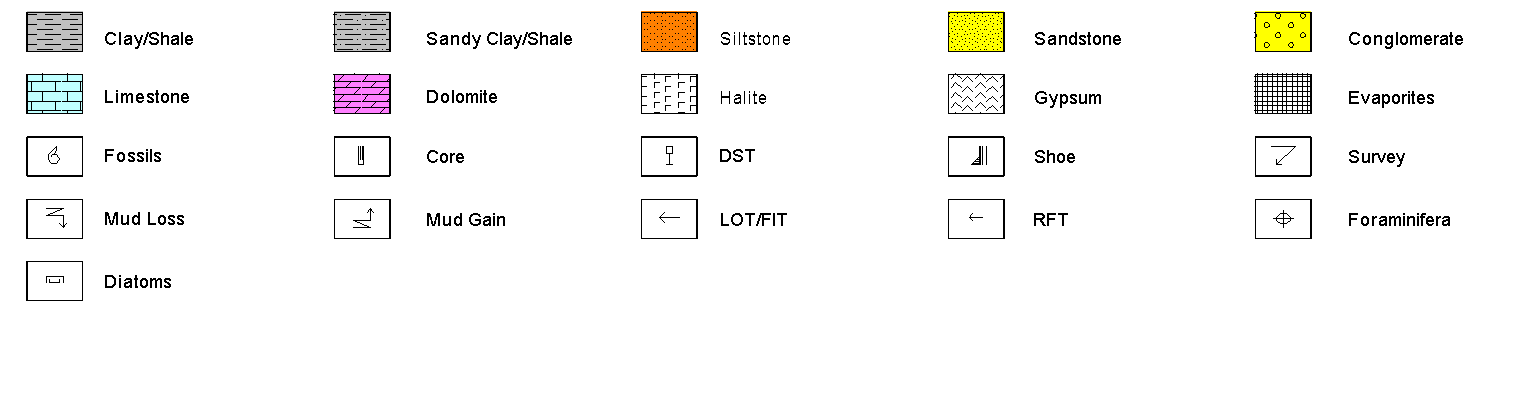

In [56]:
crop_rgb(Image.open(data_df.loc[0]["Image"]), data_df.loc[0]["Lithology Legend"])